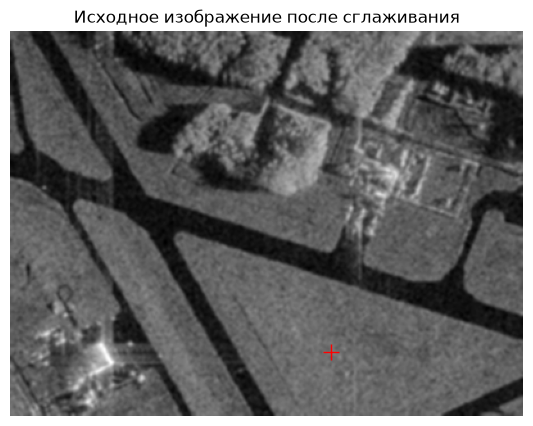

In [8]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('sar_1.jpg')

if image is None:
    raise FileNotFoundError("Положите картинку рядом с ноутбуком")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_gray = cv2.GaussianBlur(image_gray, (5, 5), 1)

plt.figure(figsize=(7, 5))
plt.imshow(image_gray, cmap='gray')
plt.plot(250, 250, 'r+', markersize=12)
plt.title('Исходное изображение после сглаживания')
plt.axis('off')
plt.show()

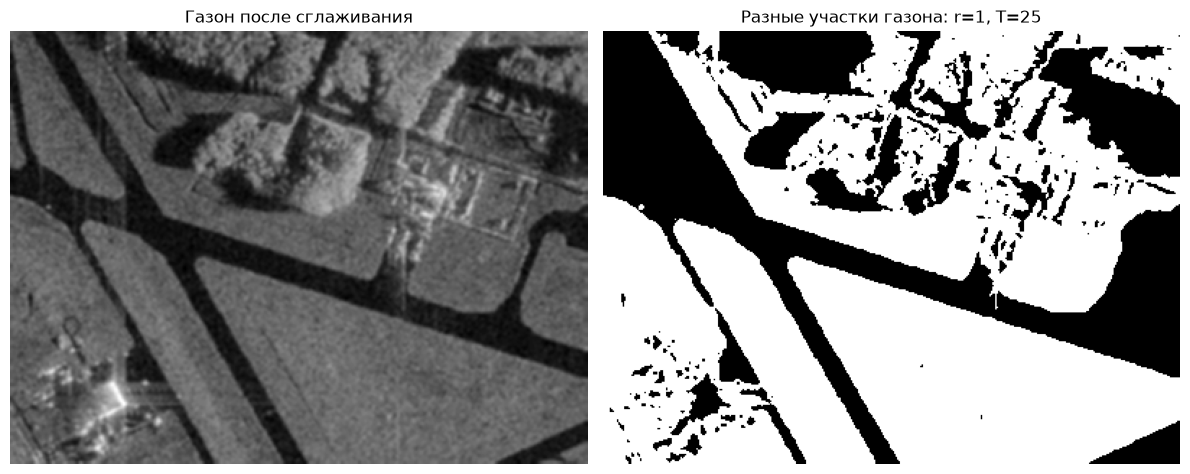

Площадь по среднему: 77432 пикселей


In [9]:
# 1. Критерий средней яркости и разрастание региона

def homo_average(img, mask, T):
    average = np.mean(img[mask > 0])
    return np.abs(img - average) <= T


def region_growing(image, seed_point, homo_fun, r, T):
    image = image.astype(np.float32)
    mask = np.zeros(image.shape, dtype=np.uint8)

    if isinstance(seed_point, tuple):
        seed_points = [seed_point]
    else:
        seed_points = seed_point

    for point in seed_points:
        mask[point[1], point[0]] = 1

    kernel = np.ones((2 * r + 1, 2 * r + 1), dtype=np.uint8)

    while True:
        neighbors = (cv2.dilate(mask, kernel) > 0) & (mask == 0)
        new_pixels = neighbors & homo_fun(image, mask, T)

        if not np.any(new_pixels):
            break

        mask[new_pixels] = 1

    return mask * 255


seed_point = [(250, 250), (220, 110), (75, 40), (190, 35),
              (150, 280), (155, 210), (140, 220), (50, 130),
              (20, 265), (298, 295)]

r = 1
T = 25

mask_avg = region_growing(image_gray, seed_point, homo_average, r, T)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title('Газон после сглаживания')

axes[1].imshow(mask_avg, cmap='gray')
axes[1].set_title(f'Разные участки газона: r={r}, T={T}')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Площадь по среднему:', np.sum(mask_avg > 0), 'пикселей')

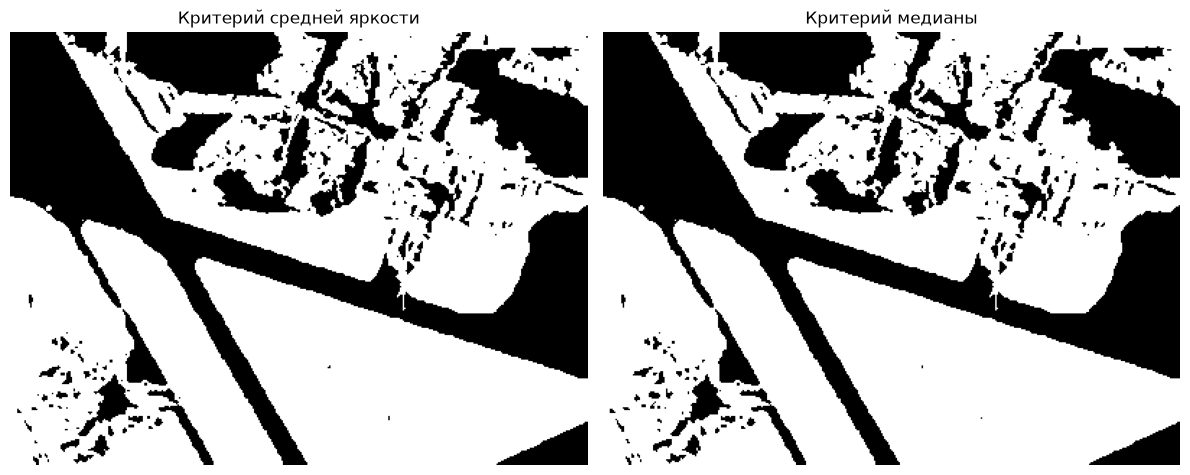

Площадь по среднему: 77432 пикселей
Площадь по медиане: 77754 пикселей


In [10]:
def homo_median(img, mask, T):
    median = np.median(img[mask > 0])
    return np.abs(img - median) <= T


mask_median = region_growing(
    image_gray, seed_point, homo_median, r, T
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(mask_avg, cmap='gray')
axes[0].set_title('Критерий средней яркости')

axes[1].imshow(mask_median, cmap='gray')
axes[1].set_title('Критерий медианы')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Площадь по среднему:', np.sum(mask_avg > 0), 'пикселей')
print('Площадь по медиане:', np.sum(mask_median > 0), 'пикселей')

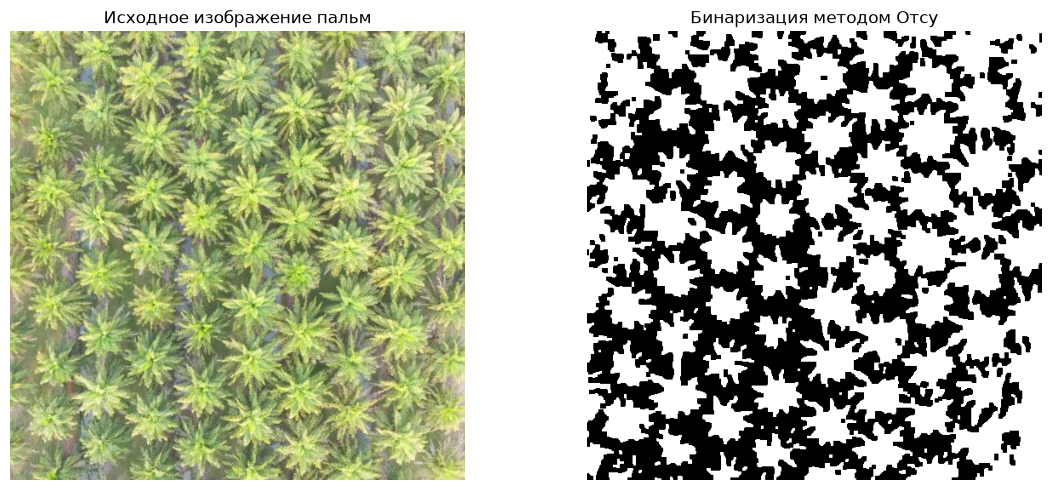

Порог Отсу: 158.0


In [11]:
palm = cv2.imread('palm_1.JPG')

if palm is None:
    raise FileNotFoundError("Изображение palm_1.JPG не найдено")

palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
palm_gray = cv2.GaussianBlur(palm_gray, (5, 5), 1)

T_otsu, thresh = cv2.threshold(
    palm_gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

kernel = np.ones((3, 3), dtype=np.uint8)

thresh = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel
)

thresh = cv2.morphologyEx(
    thresh, cv2.MORPH_CLOSE,
    np.ones((5, 5), dtype=np.uint8)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))
plt.title('Исходное изображение пальм')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Бинаризация методом Отсу')
plt.axis('off')

plt.tight_layout()
plt.show()

print('Порог Отсу:', T_otsu)

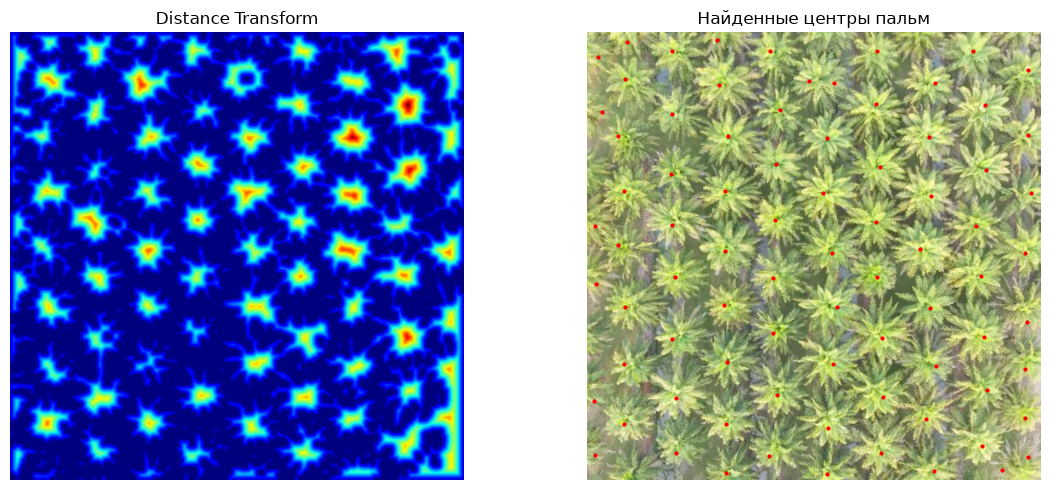

Количество найденных центров: 81


In [12]:
bordered = cv2.copyMakeBorder(
    thresh, 1, 1, 1, 1,
    cv2.BORDER_CONSTANT, value=0
)

dist = cv2.distanceTransform(
    bordered, cv2.DIST_L2, 5
)[1:-1, 1:-1]

dist = cv2.GaussianBlur(dist, (5, 5), 1)

local_max = cv2.dilate(
    dist, np.ones((31, 31), dtype=np.uint8)
)

sure_fg = np.uint8(
    (dist == local_max) & (dist > 7)
) * 255

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(dist, cmap='jet')
axes[0].set_title('Distance Transform')

axes[1].imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))

y, x = np.where(sure_fg > 0)
axes[1].plot(x, y, 'r.', markersize=4)
axes[1].set_title('Найденные центры пальм')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Количество найденных центров:', len(x))

Автоматическая оценка числа пальм: 81


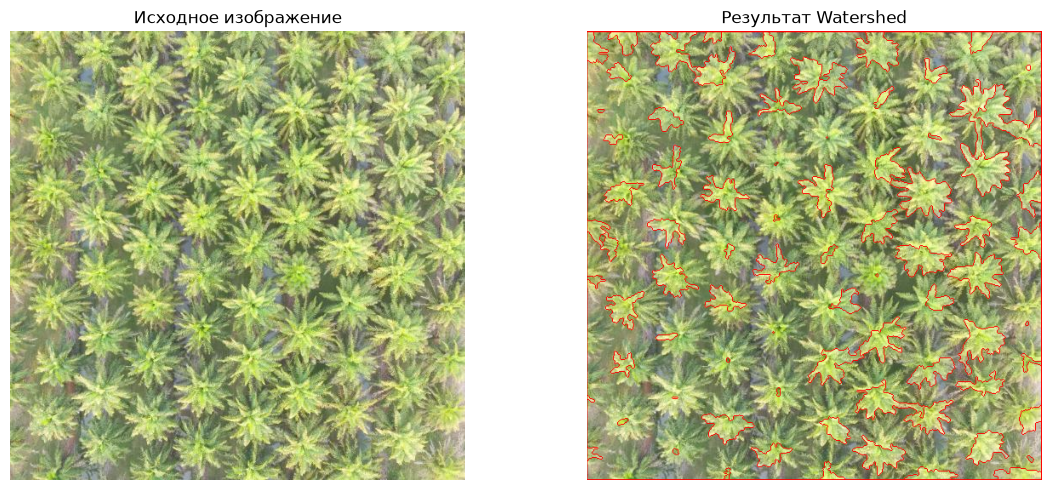

In [13]:
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1

sure_bg = cv2.dilate(thresh, kernel, iterations=2)
unknown = cv2.subtract(sure_bg, sure_fg)

markers[unknown == 255] = 0

markers = cv2.watershed(
    cv2.GaussianBlur(palm, (5, 5), 1),
    markers
)

palm_labels = np.unique(markers[markers > 1])
palm_count = len(palm_labels)

print('Автоматическая оценка числа пальм:', palm_count)

result = palm.copy()
result[markers == -1] = [0, 0, 255]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))
axes[0].set_title('Исходное изображение')

axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title('Результат Watershed')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()